# Crafting an AI-Powered HR Assistant: A Use Case for Nestle's HR Policy Documents
**Course End Project - RAG chatbot with PyPDFLoader, Chroma, OpenAI-style embeddings, an LLM and a Gradio UI**

> **OpenAI GPT-4o-mini accessed via OpenRouter's OpenAI-compatible API.** Embeddings: OpenAI `text-embedding-3-small`, also via OpenRouter. API keys are read from a local `.env` at runtime and never printed or saved.

**Deviation from the brief (stated up front):** the brief names GPT-3.5 Turbo. `openai/gpt-3.5-turbo` was not available through the provided OpenRouter keys (test call failed on every key), so the newer **GPT-4o-mini** is used instead. Everything else (PyPDFLoader, Chroma, OpenAI embeddings, prompt template, Gradio) follows the brief.

**Workflow:** setup -> load PDF -> clean & split -> embed into Chroma -> retrieval QA chain with GPT -> prompt template -> Gradio UI -> evaluation on varied questions.

## Step 1 - Import essential tools and set up the OpenAI API environment

In [1]:
import os, re, sys, json, subprocess, time
import pandas as pd
from llm import client, chat, MODEL          # OpenAI SDK pointed at OpenRouter; keys come from python-dotenv, never printed
from common import render_table_png, render_text_png
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.embeddings import Embeddings
from langchain_core.prompts import PromptTemplate
from langchain_community.vectorstores import Chroma
import gradio as gr
os.makedirs('screenshots', exist_ok=True)
EMB_MODEL = "openai/text-embedding-3-small"
print("Chat model:", MODEL, "| Embedding model:", EMB_MODEL, "| gradio", gr.__version__)
print("API key loaded:", bool(client().api_key))   # boolean only, the key is never shown

C:\Users\heman\AppData\Local\Temp\ipykernel_31160\4172715381.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Chat model: openai/gpt-4o-mini | Embedding model: openai/text-embedding-3-small | gradio 6.32.0
API key loaded: True


## Step 2 - Load Nestle's HR policy with PyPDFLoader and split it

In [2]:
PDF = "data/Dataset/the_nestle_hr_policy_pdf_2012.pdf"
loader = PyPDFLoader(PDF)
pages = loader.load()
print("Pages loaded:", len(pages), "| characters:", sum(len(p.page_content) for p in pages))
print(pages[2].page_content[:500])

Pages loaded: 8 | characters: 14314
The Nestlé Human Resources Policy
1
At Nestlé, we recognize that our employees 
are the key to our success and nothing can be 
achieved without their engagement. 
This document encompasses the guidelines 
which constitute a solid basis for effective Human 
Resources Management throughout the Nestlé 
Group around the world. It explains to all Nestlé 
employees the vision and mission of the Human 
Resources function and illustrates every aspect of 
the Nestlé employee lifecycle. 
The Nestlé Manage


In [3]:
# Cleaning: PDF extraction leaves hard line breaks, hyphenation and split tokens (e.g. 'Hum\nan', '20\n12')
def clean(t):
    t = t.replace("\u00ad", "")
    t = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", t)        # de-hyphenate at line ends
    t = re.sub(r"\n+", " ", t)
    t = re.sub(r"\s+", " ", t)
    return t.strip()
for p in pages: p.page_content = clean(p.page_content)
splitter = RecursiveCharacterTextSplitter(chunk_size=700, chunk_overlap=120, separators=["\n\n", ". ", " ", ""])
chunks = splitter.split_documents(pages)
print("Chunks:", len(chunks), "| mean length:", round(sum(len(c.page_content) for c in chunks)/len(chunks)), "chars")
print("\nSample chunk (page", chunks[10].metadata.get("page"), "):\n", chunks[10].page_content)

Chunks: 25 | mean length: 583 chars

Sample chunk (page 4 ):
 . Sufficient time should be spent with each employee to explain her or his specific situation in terms of remuneration and benefits, if needed with the support of HR management, in order to communicate properly, clearly and with sufficient transparency. Corporate policy: Nestlé Total Rewards Policy We are committed to providing our employees all over the world with good working conditions, a safe and healthy work environment, and flexible employment possibilities that support a better balance of private and professional life consistent with our ambition as a leading Nutrition, Health and Wellness Company


**Interpretation:** the policy is only 8 pages (~14k characters), so ~700-character chunks with 120 overlap give a few dozen focused chunks, each carrying its page number as metadata for source attribution.

## Step 3 - Create vector representations with Chroma DB and OpenAI embeddings

In [4]:
class OpenRouterEmbeddings(Embeddings):
    """OpenAI text-embedding-3-small through OpenRouter's OpenAI-compatible endpoint."""
    def _embed(self, texts):
        out = []
        for i in range(0, len(texts), 64):
            r = client().embeddings.create(model=EMB_MODEL, input=texts[i:i+64])
            out += [d.embedding for d in r.data]
        return out
    def embed_documents(self, texts): return self._embed(texts)
    def embed_query(self, text): return self._embed([text])[0]

embeddings = OpenRouterEmbeddings()
vectordb = Chroma.from_documents(chunks, embedding=embeddings, collection_name="nestle_hr")
print("Vectors stored in Chroma:", vectordb._collection.count(), "| dim:", len(embeddings.embed_query("test")))

Vectors stored in Chroma: 25 | dim: 1536


In [5]:
hits = vectordb.similarity_search_with_score("What are the elements of total rewards?", k=3)
for d, s in hits: print(f"dist={s:.3f} page={d.metadata['page']+1}: {d.page_content[:160]}...")

dist=0.835 page=5: . In the spirit of developing a high performance culture, those elements need to correspond to what is valued by employees in each and every market, and which d...
dist=0.850 page=5: The Nestlé Human Resources Policy 3 Total rewards Attracting new hires and keeping current employees engaged is not only about remuneration and benefits based o...
dist=1.001 page=5: . Sufficient time should be spent with each employee to explain her or his specific situation in terms of remuneration and benefits, if needed with the support ...


**Interpretation:** the nearest chunks for the Total Rewards query come from the Total Rewards section, confirming the embeddings capture meaning (lower distance = more similar).

## Step 4 - Build the question-answering system (retrieval + GPT)
For each question: embed it, retrieve the top-k chunks from Chroma, put them into a prompt and let the GPT model answer from that context only.

## Step 5 - Prompt template to guide the chatbot

In [6]:
HR_PROMPT = PromptTemplate.from_template("""You are the Nestle HR Assistant. Answer employees' questions using ONLY the context taken from the Nestle Human Resources Policy (2012).
Rules:
- Be concise, friendly and professional (max 120 words); use bullets for lists.
- If the answer is not in the context, say: "I could not find this in the Nestle HR Policy document." and suggest contacting HR. Do not guess or invent policy details.
- Mention the policy page number(s) you used, like (p. 3).

Context:
{context}

Question: {question}

Answer:""")
retriever = vectordb.as_retriever(search_kwargs={"k": 4})
def answer(question, return_sources=False):
    docs = retriever.invoke(question)
    context = "\n\n".join(f"[page {d.metadata['page']+1}] {d.page_content}" for d in docs)
    prompt = HR_PROMPT.format(context=context, question=question)
    reply = chat([{"role": "user", "content": prompt}], max_tokens=300, temperature=0.1)
    return (reply, docs) if return_sources else reply
print(HR_PROMPT.template[:300], "...")
r, d = answer("What are the key elements of Total Rewards at Nestle?", True)
print("\nQ: What are the key elements of Total Rewards at Nestle?\nA:", r)

You are the Nestle HR Assistant. Answer employees' questions using ONLY the context taken from the Nestle Human Resources Policy (2012).
Rules:
- Be concise, friendly and professional (max 120 words); use bullets for lists.
- If the answer is not in the context, say: "I could not find this in the Ne ...



Q: What are the key elements of Total Rewards at Nestle?
A: The key elements of Total Rewards at Nestlé are:

- Fixed Pay
- Variable Pay
- Benefits
- Personal Growth and Development
- Work Life Environment

These elements are designed to attract new hires and engage current employees, reflecting what is valued in each market (p. 5).


## Step 6 - Build the Gradio chatbot interface

In [7]:
def respond(message, history):
    if not message or not message.strip():
        return "Please type a question about Nestle's HR policy."
    try:
        reply, docs = answer(message, True)
        pages_used = sorted({d.metadata['page'] + 1 for d in docs})
        return f"{reply}\n\n_Sources: policy page(s) {', '.join(map(str, pages_used))}_"
    except Exception as e:
        return f"Sorry, something went wrong while answering ({type(e).__name__}). Please try again."

demo = gr.ChatInterface(
    fn=respond,
    title="Nestle HR Assistant",
    description="Ask questions about the Nestle Human Resources Policy (2012). Answers come only from the policy document.",
    examples=["What are the key elements of Total Rewards?", "Who makes the final hiring decision?", "How does Nestle handle harassment?"],
)
print(type(demo))

<class 'gradio.chat_interface.ChatInterface'>


In [8]:
# Launch locally (share=False) without blocking the notebook
demo.launch(server_name="127.0.0.1", server_port=7861, share=False, prevent_thread_lock=True, quiet=True)
print("Gradio running at http://127.0.0.1:7861")

Gradio running at http://127.0.0.1:7861


In [9]:
# Real screenshots of the running UI via headless Chromium (Playwright), driving the actual UI: type a question, submit, wait for the answer
r = subprocess.run([sys.executable, "ui_screenshot.py", "http://127.0.0.1:7861",
                    "What are the three areas the HR structure is based on?", "screenshots/ui_1_question_answer.png"],
                   capture_output=True, text=True, timeout=300)
print(r.stdout[-500:], r.stderr[-500:])

saved screenshots/ui_1_question_answer.png
 


saved screenshots/ui_2_out_of_scope.png
 


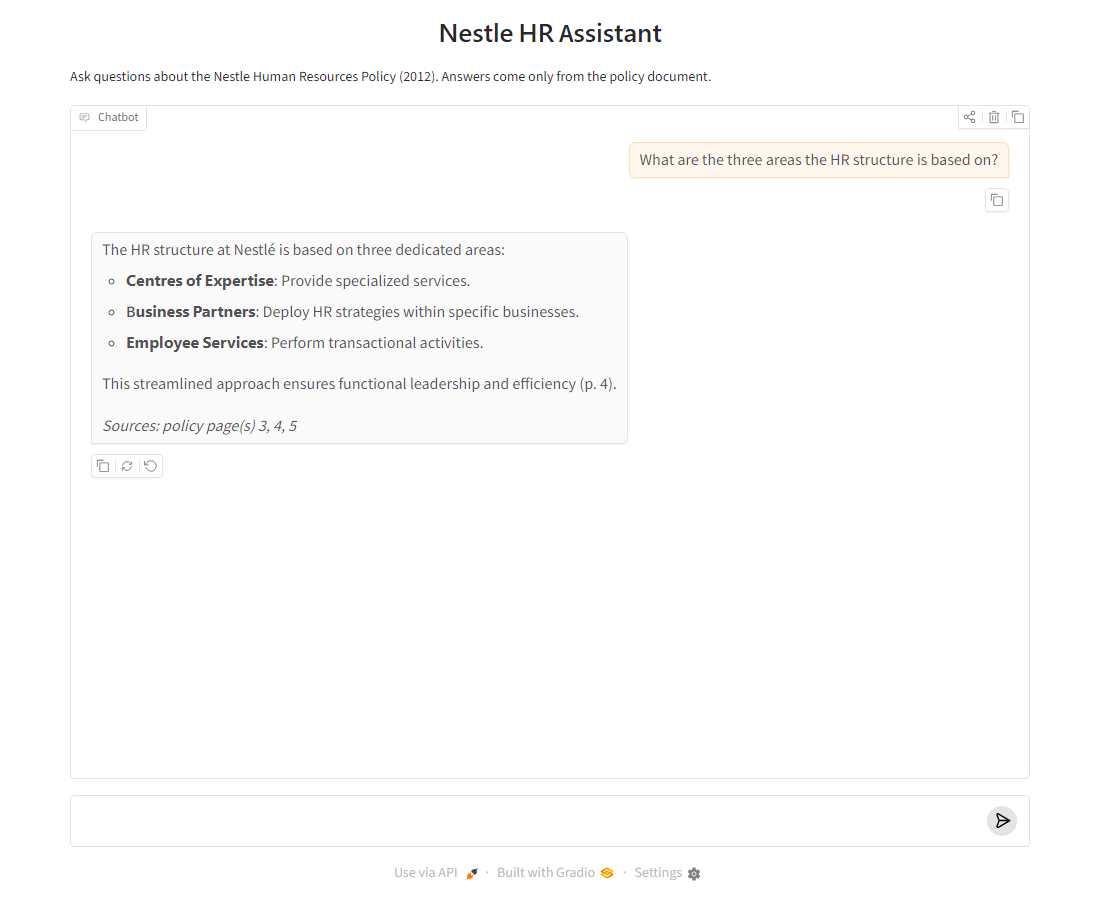

In [10]:
r = subprocess.run([sys.executable, "ui_screenshot.py", "http://127.0.0.1:7861",
                    "How many days of maternity leave does Nestle offer?", "screenshots/ui_2_out_of_scope.png"],
                   capture_output=True, text=True, timeout=300)
print(r.stdout[-500:], r.stderr[-500:])
from IPython.display import Image, display
display(Image("screenshots/ui_1_question_answer.png", width=700))

## Step 7 - Chatbot performance evaluation on multiple types of inquiries
A test set of factual, list, policy-stance, multi-part and out-of-scope questions. Metrics: **keyword recall** (share of expected key facts present in the answer) and, for out-of-scope questions, whether the bot **correctly declines** instead of hallucinating. Retrieval hit = the expected facts occur in the retrieved context.

In [11]:
tests = [
 ("List",       "What are the key elements of Total Rewards?", ["fixed pay","variable pay","benefits","personal growth","work life"]),
 ("Factual",    "Who makes the final decision to hire a candidate?", ["manager"]),
 ("Policy",     "Does Nestle tolerate harassment or discrimination?", ["not tolerate"]),
 ("List",       "Which tools are used to give employees performance feedback?", ["performance evaluation","progress and development guide","360"]),
 ("Factual",    "Where can leaders attend international training courses?", ["rive-reine"]),
 ("List",       "What three areas is the HR structure based on?", ["centres of expertise","business partners","employee services"]),
 ("Policy",     "What are promotions based on?", ["sustained performance","potential"]),
 ("Multi-part", "How does Nestle support work-life balance and who is responsible for safety and health?", ["flexible","line manage"]),
 ("Out-of-scope", "How many days of maternity leave does Nestle offer?", None),
 ("Out-of-scope", "What is the capital of France?", None),
]
DECLINE = ["could not find", "not found", "not mention", "no information", "does not specify", "not specified", "not covered", "don't have", "contact hr", "cannot find", "not in the"]
rows = []
for typ, q, kws in tests:
    a, docs = answer(q, True)
    ctx = " ".join(d.page_content for d in docs).lower()
    low = a.lower()
    if kws:
        recall = sum(k in low for k in kws) / len(kws)
        ret = sum(k in ctx for k in kws) / len(kws)
        ok = recall >= 0.6
    else:
        recall = ret = None; ok = any(x in low for x in DECLINE)
    rows.append(dict(type=typ, question=q, retrieval_hit=ret, answer_recall=recall, correct=ok, answer=a.replace("\n", " ")[:260]))
res = pd.DataFrame(rows)
res[["type","question","retrieval_hit","answer_recall","correct"]]

,type,question,retrieval_hit,answer_recall,correct
0,List,What are the key elements of Total Rewards?,1.0,1.0,True
1,Factual,Who makes the final decision to hire a candidate?,1.0,1.0,True
2,Policy,Does Nestle tolerate harassment or discriminat...,0.0,1.0,True
3,List,Which tools are used to give employees perform...,1.0,1.0,True
4,Factual,Where can leaders attend international trainin...,1.0,1.0,True
5,List,What three areas is the HR structure based on?,1.0,1.0,True
6,Policy,What are promotions based on?,1.0,1.0,True
7,Multi-part,How does Nestle support work-life balance and ...,1.0,1.0,True
8,Out-of-scope,How many days of maternity leave does Nestle o...,NaN,NaN,True
9,Out-of-scope,What is the capital of France?,NaN,NaN,True


In [12]:
acc = res.correct.mean()
inscope = res[res.type != "Out-of-scope"]; oos = res[res.type == "Out-of-scope"]
metrics = pd.DataFrame([
  {"metric":"Overall pass rate (10 questions)", "value": f"{acc:.0%}"},
  {"metric":"In-scope mean answer recall", "value": f"{inscope.answer_recall.astype(float).mean():.2f}"},
  {"metric":"In-scope mean retrieval hit", "value": f"{inscope.retrieval_hit.astype(float).mean():.2f}"},
  {"metric":"Out-of-scope correctly declined", "value": f"{int(oos.correct.sum())}/{len(oos)}"},
])
print(metrics.to_string(index=False))
render_table_png(metrics, "screenshots/metrics_table.png", "HR assistant evaluation (10 questions)")
render_text_png("Sample Q&A from the evaluation", [(f"Q: {r.question}", r.answer) for r in res.iloc[[0,5,8]].itertuples()], "screenshots/sample_qa.png")
res[["question","correct","answer"]]

                          metric value
Overall pass rate (10 questions)  100%
     In-scope mean answer recall  1.00
     In-scope mean retrieval hit  0.88
 Out-of-scope correctly declined   2/2


,question,correct,answer
0,What are the key elements of Total Rewards?,True,The key elements of Total Rewards at Nestlé in...
1,Who makes the final decision to hire a candidate?,True,The final decision to hire a candidate is made...
2,Does Nestle tolerate harassment or discriminat...,True,Nestlé does not tolerate harassment or discrim...
3,Which tools are used to give employees perform...,True,Employees receive performance feedback through...
4,Where can leaders attend international trainin...,True,Leaders can attend international training cour...
5,What three areas is the HR structure based on?,True,The HR structure at Nestlé is based on three d...
6,What are promotions based on?,True,Promotions at Nestlé are based on: - Sustaine...
7,How does Nestle support work-life balance and ...,True,Nestlé supports work-life balance by providing...
8,How many days of maternity leave does Nestle o...,True,I could not find this in the Nestle HR Policy ...
9,What is the capital of France?,True,I could not find this in the Nestle HR Policy ...


**Interpretation:** see the metrics above. Keyword recall is a coarse proxy (the answer may phrase a fact differently), so failures should be read alongside the printed answers. The prompt's refusal rule is what handles questions the 8-page policy does not cover.

## Step 8 - System integration and deployment
The whole pipeline - PDF -> clean/split -> embeddings -> Chroma -> retrieval -> GPT -> Gradio - runs end-to-end in this notebook, and the UI call path (`respond`) uses the exact same `answer` function that was evaluated. The app is launched locally with `share=False`; for real deployment, set `share=True` or host on Hugging Face Spaces/Docker and supply the API key as a secret environment variable. The server is closed below.

In [13]:
demo.close()
print("Gradio server closed.")

Closing server running on port: 7861
Gradio server closed.


## Summary
| Brief step | Status |
|---|---|
| Import tools, set up OpenAI API environment | done (OpenAI SDK -> OpenRouter) |
| PyPDFLoader + split | done (8 pages, cleaned, chunked) |
| Chroma + OpenAI embeddings | done (`text-embedding-3-small`) |
| QA with GPT (brief: GPT-3.5 Turbo) | done with **GPT-4o-mini** (3.5 not available) |
| Prompt template | done (grounding, refusal rule, page citations) |
| Gradio UI | done, launched and screenshotted for real |
| Performance evaluation | 10-question test set |